# NormalObjects: Strict Complaint Processor (LangGraph)

## Step 1: Setup and State Definition

A complaint moves through a fixed pipeline: intake → validate → investigate → resolve → close.
Every node reads and updates one shared **state**, so we define that state first.

In [10]:
%pip install -q langgraph langchain-core langchain-openai python-dotenv

Note: you may need to restart the kernel to use updated packages.


In [22]:
import os
import operator
from typing import Annotated, TypedDict, List, Optional

from dotenv import load_dotenv
from langchain_core.messages import HumanMessage
from langchain_openai import ChatOpenAI
from langgraph.graph import StateGraph, START, END

load_dotenv()  # expects OPENAI_API_KEY in a local .env (never commit it)

llm = ChatOpenAI(model="gpt-4o-mini", temperature=0)

In [12]:
class ComplaintState(TypedDict):
    """Shared state passed between every node in the workflow."""
    complaint: str                  # raw user input
    category: Optional[str]         # set by intake: portal | monster | psychic | environmental | other
    is_valid: Optional[bool]        # set by validate: did it pass the rules?
    validation_reason: Optional[str]
    evidence: List[str]             # set by investigate: facts the resolution is grounded in
    resolution: Optional[str]       # set by resolve: the final answer
    status: str                     # intake | validated | rejected | investigating | resolved | closed
    # Annotated reducer: returned lists are APPENDED to the existing one instead of overwriting it
    workflow_path: Annotated[List[str], operator.add]  # trace of visited nodes, for proof/visualization

In [13]:
# Sanity check: build an initial state
initial_state: ComplaintState = {
    "complaint": "The Downside Up portal opens at different times each day. How do I predict when?",
    "category": None,
    "is_valid": None,
    "validation_reason": None,
    "evidence": [],
    "resolution": None,
    "status": "new",
    "workflow_path": [],
}
initial_state

{'complaint': 'The Downside Up portal opens at different times each day. How do I predict when?',
 'category': None,
 'is_valid': None,
 'validation_reason': None,
 'evidence': [],
 'resolution': None,
 'status': 'new',
 'workflow_path': []}

## Step 2: Define Workflow Nodes

Each node is a function `state -> state`. Design choices:
- **intake** uses the LLM (fuzzy task: categorize).
- **validate** is plain rules, no LLM (strict task: the gate must be deterministic).
- **investigate** pulls facts from a small lore base, so the answer is grounded in inspectable evidence.
- **resolve** may only use that evidence.

In [58]:
VALID_CATEGORIES = {"portal", "monster", "psychic", "environmental"}

def intake_node(state: ComplaintState) -> ComplaintState:
    """Step 1: Intake - parse and categorize the complaint"""
    print("\n[INTAKE] Processing complaint...")
    prompt = f"""Categorize this Downside Up complaint into one of these categories:
- portal: Issues with portal timing, location, or behavior
- monster: Issues with creature behavior (demogorgons, etc.)
- psychic: Issues with psychic abilities or limitations
- environmental: Issues with electricity, weather, or physical environment
- other: Anything else

Complaint: {state["complaint"]}

Respond with ONLY the category name (portal, monster, psychic, environmental, or other)."""
    category = llm.invoke([HumanMessage(content=prompt)]).content.strip().lower()
    print(f"[INTAKE] Categorized as: {category}")
    return {"category": category, "workflow_path": ["intake"], "status": "intake"}


def validate_node(state: ComplaintState) -> ComplaintState:
    """Step 2: Validate - deterministic rules, no LLM"""
    print("\n[VALIDATE] Checking rules...")
    complaint, category = state["complaint"].strip(), state["category"]
    if len(complaint) < 15:
        valid, reason = False, "Complaint too short to process"
    elif category not in VALID_CATEGORIES:
        valid, reason = False, f"Category '{category}' is outside NormalObjects jurisdiction"
    else:
        valid, reason = True, f"Passed: {len(complaint)} chars (min 15), category '{category}' is supported"
    print(f"[VALIDATE] {'PASS' if valid else 'REJECT'}: {reason}")
    return {"is_valid": valid, "validation_reason": reason, "workflow_path": ["validate"],
            "status": "validated" if valid else "rejected"}

In [15]:
# Small source-of-truth lore base. Evidence must come from here.
LORE = {
    "portal": [
        "Gates to the Upside Down are unstable and open irregularly, not on a fixed schedule.",
        "Gate activity correlates with Vecna's and the Mind Flayer's activity, not clock time.",
    ],
    "monster": [
        "Demogorgons hunt alone as predators but are directed by the Mind Flayer's hive mind.",
        "Under Mind Flayer control, creatures coordinate; without it they act on instinct.",
    ],
    "psychic": [
        "Eleven's powers are limited by concentration, emotional state, and physical stamina.",
        "Large or heavy objects cost far more energy, often causing nosebleeds and exhaustion.",
    ],
    "environmental": [
        "Electricity flickers near Upside Down activity; lights and power lines react to creature presence.",
        "The Upside Down mirrors Hawkins but is cold, spore-filled, and electrically disturbed.",
    ],
}

def investigate_node(state: ComplaintState) -> ComplaintState:
    """Step 3: Investigate - gather evidence from the lore base"""
    print("\n[INVESTIGATE] Gathering evidence...")
    evidence = LORE.get(state["category"], [])
    for e in evidence:
        print(f"[INVESTIGATE]  - {e}")
    return {"evidence": evidence, "workflow_path": ["investigate"], "status": "investigating"}


def resolve_node(state: ComplaintState) -> ComplaintState:
    """Step 4: Resolve - answer using ONLY the gathered evidence"""
    print("\n[RESOLVE] Drafting resolution...")
    evidence = "\n".join(f"- {e}" for e in state["evidence"])
    prompt = f"""Answer the complaint using ONLY the evidence below.
If the evidence does not answer it, say so. Do not add outside facts. Max 3 sentences.

Complaint: {state["complaint"]}

Evidence:
{evidence}"""
    resolution = llm.invoke([HumanMessage(content=prompt)]).content.strip()
    print(f"[RESOLVE] {resolution}")
    return {"resolution": resolution, "workflow_path": ["resolve"], "status": "resolved"}


def close_node(state: ComplaintState) -> ComplaintState:
    """Step 5: Close - confirm completion (also handles rejected complaints)"""
    print("\n[CLOSE] Closing complaint...")
    resolution = state["resolution"] or f"Rejected: {state['validation_reason']}"
    print(f"[CLOSE] Final status: closed ({'rejected' if state['status'] == 'rejected' else 'resolved'})")
    return {"resolution": resolution, "workflow_path": ["close"], "status": "closed"}

## Step 3: Build the Graph

Flow: `intake → validate → (investigate → resolve →) close`.
After `validate`, a **conditional edge** reads `is_valid` from state and picks the next node. Rejected complaints skip straight to `close`.

In [16]:
def route_after_validation(state: ComplaintState) -> str:
    """Routing function: returns the NAME of the next node."""
    return "investigate" if state["is_valid"] else "close"

In [59]:
workflow = StateGraph(ComplaintState)

# Nodes
workflow.add_node("intake", intake_node)
workflow.add_node("validate", validate_node)
workflow.add_node("investigate", investigate_node)
workflow.add_node("resolve", resolve_node)
workflow.add_node("close", close_node)

# Edges
workflow.add_edge(START, "intake")
workflow.add_edge("intake", "validate")
workflow.add_conditional_edges(
    "validate",
    route_after_validation,
    {"investigate": "investigate", "close": "close"},  # return value -> node
)
workflow.add_edge("investigate", "resolve")
workflow.add_edge("resolve", "close")
workflow.add_edge("close", END)

app = workflow.compile()

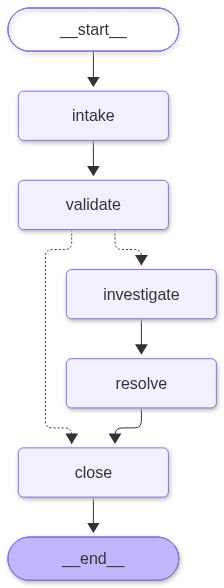

In [40]:
from IPython.display import Image, display

# Inspect the graph structure
graph = app.get_graph()
# print(graph.draw_mermaid())


display(Image(graph.draw_mermaid_png()))



## Step 4: Test the Workflow

Two test lists:
- **`langgraph_complaints`**: the five from this lab's instructions.
- **`langchain_complaints`**: the six used in the LangChain lab, so both approaches can be compared on identical input in Step 6.

In [41]:
langgraph_complaints = [
    "The Downside Up portal opens at different times each day. How do I predict when?",
    "Demogorgons sometimes work together and sometimes fight. What's their deal?",
    "El can move things with her mind but can't lift heavy rocks. Why?",
    "Why do creatures and power lines react so strangely together?",
    "This is not a valid complaint about something random",  # should be rejected
]

# Copied from the LangChain lab (normalobjects_langchain.ipynb)
langchain_complaints = [
    "There is a glowing portal in my garage and it keeps flickering my lights. Help!",
    "Monsters keep stealing the Eggo waffles from my freezer every night.",
    "My teenage daughter has psychic powers and keeps breaking the TV with her mind.",
    "My neighbour's dog barks at 3am every single night.",
    "My friends and I can't agree on a strategy for our bike trip through the woods.",
    "What is the capital of France?",
]

In [52]:
def run_workflow(complaint: str) -> ComplaintState:
    """Run one complaint through the graph and return the final state."""
    initial: ComplaintState = {
        "complaint": complaint, "category": None, "is_valid": None,
        "validation_reason": None, "evidence": [], "resolution": None,
        "status": "new", "workflow_path": [],
    }
    return app.invoke(initial)


def run_tests(complaints: list[str]) -> list[ComplaintState]:
    results = []
    for i, complaint in enumerate(complaints, 1):
        print(f"\n{'=' * 70}\nComplaint {i}: {complaint}")
        results.append(run_workflow(complaint))
    return results

In [53]:
print("Testing workflow with the LAB complaints...")
langgraph_results = run_tests(langgraph_complaints)

Testing workflow with the LAB complaints...

Complaint 1: The Downside Up portal opens at different times each day. How do I predict when?

[INTAKE] Processing complaint...
[INTAKE] Categorized as: portal

[VALIDATE] Checking rules...
[VALIDATE] PASS: Passed all rules

[INVESTIGATE] Gathering evidence...
[INVESTIGATE]  - Gates to the Upside Down are unstable and open irregularly, not on a fixed schedule.
[INVESTIGATE]  - Gate activity correlates with Vecna's and the Mind Flayer's activity, not clock time.

[RESOLVE] Drafting resolution...
[RESOLVE] The Downside Up portal opens irregularly and is influenced by the unstable nature of the gates, which do not operate on a fixed schedule. Additionally, the timing of the gate activity is linked to the activities of Vecna and the Mind Flayer, rather than specific clock times. Therefore, it is not possible to predict when the portal will open.

[CLOSE] Closing complaint...
[CLOSE] Final status: closed (resolved)

Complaint 2: Demogorgons somet

In [54]:
print("Testing workflow with the LANGCHAIN-lab complaints...")
langchain_results = run_tests(langchain_complaints)

Testing workflow with the LANGCHAIN-lab complaints...

Complaint 1: There is a glowing portal in my garage and it keeps flickering my lights. Help!

[INTAKE] Processing complaint...
[INTAKE] Categorized as: portal

[VALIDATE] Checking rules...
[VALIDATE] PASS: Passed all rules

[INVESTIGATE] Gathering evidence...
[INVESTIGATE]  - Gates to the Upside Down are unstable and open irregularly, not on a fixed schedule.
[INVESTIGATE]  - Gate activity correlates with Vecna's and the Mind Flayer's activity, not clock time.

[RESOLVE] Drafting resolution...
[RESOLVE] The glowing portal in your garage may be a gate to the Upside Down, which is known to be unstable and open irregularly. This instability could be causing the flickering lights. Unfortunately, there is no specific solution provided for this issue in the evidence.

[CLOSE] Closing complaint...
[CLOSE] Final status: closed (resolved)

Complaint 2: Monsters keep stealing the Eggo waffles from my freezer every night.

[INTAKE] Processing

In [55]:
# Compact overview of both runs (kept for Steps 5 and 6)
for name, results in [("LAB", langgraph_results), ("LANGCHAIN LAB", langchain_results)]:
    print(f"\n{name}")
    for r in results:
        print(f"  {r['category']:<14} {' -> '.join(r['workflow_path']):<50} {r['complaint'][:45]}")


LAB
  portal         intake -> validate -> investigate -> resolve -> close The Downside Up portal opens at different tim
  monster        intake -> validate -> investigate -> resolve -> close Demogorgons sometimes work together and somet
  psychic        intake -> validate -> investigate -> resolve -> close El can move things with her mind but can't li
  environmental  intake -> validate -> investigate -> resolve -> close Why do creatures and power lines react so str
  other          intake -> validate -> close                        This is not a valid complaint about something

LANGCHAIN LAB
  portal         intake -> validate -> investigate -> resolve -> close There is a glowing portal in my garage and it
  monster        intake -> validate -> investigate -> resolve -> close Monsters keep stealing the Eggo waffles from 
  psychic        intake -> validate -> investigate -> resolve -> close My teenage daughter has psychic powers and ke
  other          intake -> validate -> close   

## Step 5: Visualize Workflow Execution

Three views:
1. **Graph structure**: what paths *can* happen.
2. **Step-by-step trace**: what each node *changed* in state for one complaint (via `app.stream`).
3. **Path summary**: which route every complaint actually took.

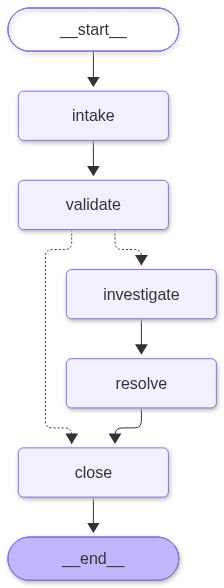

In [56]:
# 1. Graph structure (renders a PNG via mermaid.ink; falls back to text if offline)
from IPython.display import Image, display
try:
    display(Image(app.get_graph().draw_mermaid_png()))
except Exception as e:
    print(f"PNG render failed ({type(e).__name__}); Mermaid text instead:\n")
    print(app.get_graph().draw_mermaid())

In [61]:
# 2. Step-by-step trace: stream_mode="updates" yields only what each node returned
def trace_workflow(complaint: str):
    initial: ComplaintState = {
        "complaint": complaint, "category": None, "is_valid": None,
        "validation_reason": None, "evidence": [], "resolution": None,
        "status": "new", "workflow_path": [],
    }
    print(f"QUERY: {complaint}\n")
    for step, update in enumerate(app.stream(initial, stream_mode="updates"), 1):
        for node, changes in update.items():
            print(f"{step}. [{node.upper()}]")
            for key, value in changes.items():
                if key == "workflow_path":
                    continue  # redundant here; the numbered steps already show the path
                print(f"     {key}: {value}")

print("#" * 70, "\nGROUNDED EXAMPLE (accepted complaint)")
trace_workflow(langgraph_complaints[0])
print("\n" + "#" * 70, "\nREJECTED EXAMPLE")
trace_workflow(langgraph_complaints[4])
print("\n" + "#" * 70, "\npsychic daughter complaint")
trace_workflow(langchain_complaints[2])   # psychic daughter

###################################################################### 
GROUNDED EXAMPLE (accepted complaint)
QUERY: The Downside Up portal opens at different times each day. How do I predict when?


[INTAKE] Processing complaint...
[INTAKE] Categorized as: portal
1. [INTAKE]
     category: portal
     status: intake

[VALIDATE] Checking rules...
[VALIDATE] PASS: Passed: 80 chars (min 15), category 'portal' is supported
2. [VALIDATE]
     is_valid: True
     validation_reason: Passed: 80 chars (min 15), category 'portal' is supported
     status: validated

[INVESTIGATE] Gathering evidence...
[INVESTIGATE]  - Gates to the Upside Down are unstable and open irregularly, not on a fixed schedule.
[INVESTIGATE]  - Gate activity correlates with Vecna's and the Mind Flayer's activity, not clock time.
3. [INVESTIGATE]
     evidence: ['Gates to the Upside Down are unstable and open irregularly, not on a fixed schedule.', "Gate activity correlates with Vecna's and the Mind Flayer's activity, not

In [48]:
# 3. Path summary across all runs
from collections import Counter

all_results = langgraph_results + langchain_results
paths = Counter(" -> ".join(r["workflow_path"]) for r in all_results)
print("Routes taken:")
for path, n in paths.most_common():
    print(f"  {n}x  {path}")

print("\nCategory counts:", dict(Counter(r["category"] for r in all_results)))
rejected = [r["complaint"] for r in all_results if r["is_valid"] is False]
print(f"\nRejected ({len(rejected)}/{len(all_results)}):")
for c in rejected:
    print("  -", c)

Routes taken:
  7x  intake -> validate -> investigate -> resolve -> close
  4x  intake -> validate -> close

Category counts: {'portal': 2, 'monster': 2, 'psychic': 2, 'environmental': 1, 'other': 4}

Rejected (4/11):
  - This is not a valid complaint about something random
  - My neighbour's dog barks at 3am every single night.
  - My friends and I can't agree on a strategy for our bike trip through the woods.
  - What is the capital of France?


## Step 6: Compare with the LangChain Approach

LangChain = an agent that picks tools freely. 
LangGraph = a fixed workflow where code controls the route.

| | LangChain agent | LangGraph workflow |
|---|---|---|
| **Who decides the next step** | The LLM, per request | The graph; the LLM only fills in values (category, answer) |
| **Possible paths** | Open-ended: any tool order, any number of calls | Two: full pipeline, or `intake -> validate -> close` |
| **Scope** | Whatever the tools can plausibly handle; nothing is rejected | Explicit gate: 4 categories, other = rejected (4 of 11 here) |
| **Evidence** | Tool outputs, picked and queried by the LLM | Lore looked up by category, same every time |
| **Repeatability** | Varies between runs (tool choice, random replies) | Same route for the same category; only LLM wording varies |
| **Traceability** | Reconstruct from message history | `workflow_path` and per-node state updates are built in |
| **Handles off-pattern input** | Yes: bike trip got party wisdom, any problem can get a spell | No: bike trip and dog complaint are rejected |

### Where each one failed on the psychic complaint

- **LangChain:** the keyword lookup missed (`psychic` vs `psychics`) and the agent reported "no record exists". Confident, wrong, and the agent couldn't tell a failed lookup from a real absence.
- **LangGraph:** category lookup can't miss, so evidence was found. But the evidence is about Eleven's limits, not a daughter breaking a TV. The resolver either stretched it ("manage her concentration") or contradicted the user ("unlikely she is breaking the TV"). Right topic, wrong fit.

Both produce a fluent answer that sounds supported. The graph's failure is subtler: the evidence is real, the answer isn't actually backed by it.

### What the comparison shows

- **Scope is decided in different places.** The graph decides before any evidence is gathered, in code you can read. The agent decides implicitly while running, visible only afterwards in the tool calls.
- **The graph fails by refusing, the agent by answering.** Refusals are visible in the path. Over-confident answers are harder to spot.
- **The graph's gate still depends on the LLM.** Enforcement is deterministic, but the category comes from the intake LLM, so a misclassification becomes a wrong rejection or wrong evidence.
- **Grounding is stronger in the graph, relevance is not.** Evidence always comes from `LORE`, and the resolver can say "evidence doesn't cover this" (it did for the Eggo complaint). Nothing checks that the evidence fits the question before it reaches the resolver.

**Use the workflow** when you need predictable, auditable handling and can enumerate the categories. **Use the agent** when inputs are open-ended and a wrong refusal costs more than a creative answer.